# Experiment summary

This notebook trains feedforward neural networks (FNNs) to classify AG News articles into World, Sports, Business, and Sci/Tech. TF-IDF features are used to compare the original text, HTML-artifact cleaning, and a unigram-plus-bigram representation. The training set contains 96,000 articles, the development set 24,000, and the held-out test set 7,600.

## Development-set comparison

| Experiment | TF-IDF representation | Logistic Regression accuracy | Best FNN validation accuracy |
|---|---|---:|---:|
| 1. Baseline | Original text, unigrams | 91.81% | 92.49% (dropout) |
| 2. HTML cleanup | Cleaned text, unigrams | 91.90% | 92.38% (dropout) |
| 3. Bigrams | Cleaned text, unigrams and bigrams (up to 100,000 features) | 91.82% | 92.38% (early stopping) |

## Held-out test results (Experiment 3)

| Model | Test accuracy |
|---|---:|
| FNN with early stopping | 91.96% |
| Logistic Regression | 91.39% |

The FNN leads Logistic Regression by 0.57 percentage points on this test set. HTML-artifact cleanup produced only a small development-set gain for Logistic Regression (+0.09 points), while adding bigrams did not improve on that result. The FNN reached its best validation performance early; training for more epochs reduced validation performance as training loss continued to fall, indicating overfitting. Sports was the easiest class, while Business and Sci/Tech had the lowest F1 scores in the initial FNN validation report (both 0.90).

# Imports

In [1]:
import numpy as np
import pandas as pd

from datasets import load_dataset
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import accuracy_score, classification_report

In [2]:
dataset = load_dataset("fancyzhx/ag_news")

In [3]:
full_train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

full_train_df.head()

,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [4]:
full_train_df["cleaned_text"] = full_train_df["text"].str.replace("\\", " ", regex=False)

In [5]:
from sklearn.model_selection import train_test_split

train_df, dev_df = train_test_split(
    full_train_df,
    test_size = 0.2,
    random_state = 42,
    stratify=full_train_df["label"]
)

In [6]:
print(f"train_df shape: {train_df.shape}")
print(f"dev_df shape: {dev_df.shape}")

train_df shape: (96000, 3)
dev_df shape: (24000, 3)


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()

X_train = vectorizer.fit_transform(train_df["cleaned_text"])
X_dev = vectorizer.transform(dev_df["cleaned_text"])

y_train = train_df["label"]
y_dev = dev_df["label"]

In [8]:
print("X_train:", X_train.shape)
print("X_dev:", X_dev.shape)
print("y_train:", y_train.shape)
print("y_dev:", y_dev.shape)

X_train: (96000, 60004)
X_dev: (24000, 60004)
y_train: (96000,)
y_dev: (24000,)


In [9]:
class NewsDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = torch.tensor(y.to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        x = self.X[index].toarray().flatten()
        x = torch.tensor(x, dtype=torch.float32)
        return x, self.y[index]

In [10]:
train_dataset = NewsDataset(X_train, y_train)
dev_dataset = NewsDataset(X_dev, y_dev)

In [11]:
sample_X, sample_y = train_dataset[0]

print(f"Feature shape: {sample_X.shape}")
print(f"Label: {sample_y}")
print(f"Tensor dtype: {sample_X.dtype}")

Feature shape: torch.Size([60004])
Label: 1
Tensor dtype: torch.float32


In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=64,
    shuffle=True
)

In [13]:
X_batch, y_batch = next(iter(train_loader))

print(f"batch features: {X_batch.shape}")
print(f"batch labels: {y_batch.shape}")

batch features: torch.Size([64, 60004])
batch labels: torch.Size([64])


### Connecting the DataLoader to the neural network

In [14]:
class NewsClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()


        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, X):
        return self.network(X)

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [16]:
model = NewsClassifier(
    input_size=60004,
    hidden_size=128,
    num_classes=4
)

model = model.to(device)

print(model)

NewsClassifier(
  (network): Sequential(
    (0): Linear(in_features=60004, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=4, bias=True)
  )
)


In [17]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

outputs = model(X_batch)
print("Input shape:", X_batch.shape)
print("Output shape:", outputs.shape)
print("Outputs:", outputs[:2])

Input shape: torch.Size([64, 60004])
Output shape: torch.Size([64, 4])
Outputs: tensor([[ 0.0598,  0.0839,  0.0412, -0.0223],
        [ 0.0604,  0.0835,  0.0413, -0.0238]], device='cuda:0',
       grad_fn=<SliceBackward0>)


In [18]:
loss_function = nn.CrossEntropyLoss()

In [19]:
loss = loss_function(outputs, y_batch)
print(f"Loss: {loss.item()}")

Loss: 1.3930472135543823


### Introducing the optimizer

In [20]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [21]:
model.train()

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# forward prop
outputs = model(X_batch)

# get the loss
loss = loss_function(outputs, y_batch)

# clearing previous gradients
optimizer.zero_grad()

# claculate gradients
loss.backward()

# update params
optimizer.step()

In [22]:
loss.item()

1.3837224245071411

In [23]:
model.train()

total_loss = 0
total_samples = 0

for X_batch, y_batch in train_loader:

    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    outputs = model(X_batch)

    loss = loss_function(outputs, y_batch)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


    total_loss += loss.item() * X_batch.size(0)
    total_samples += X_batch.size(0)

epoch_loss = total_loss / total_samples

print(f"Training Loss: {epoch_loss:.4f}")

Training Loss: 0.3409


In [24]:
model.eval()

total_loss = 0
total_correct = 0
total_samples = 0

with torch.no_grad():

    for X_batch, y_batch in dev_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)

        loss = loss_function(outputs, y_batch)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * X_batch.size(0)
        total_correct += (predictions == y_batch).sum().item()
        total_samples += X_batch.size(0)

dev_loss = total_loss / total_samples
dev_accuracy = total_correct / total_samples

print(f"Validation Loss: {dev_loss:.4f}")
print(f"Validation Accuracy: {dev_accuracy:.4f}")

Validation Loss: 0.2271
Validation Accuracy: 0.9236


After the first epoch, the FNN reached 92.36% validation accuracy.

Next, train for five epochs in total (four additional epochs) to see whether validation performance improves.

In [25]:
history = {
    "train_loss": [0.3430],
    "val_loss": [0.2265],
    "val_accuracy": [0.9242]
}

In [26]:
num_epochs = 4

for epoch in range(num_epochs):

    # -----------------------
    #      training
    # -----------------------
    model.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)
        loss = loss_function(outputs, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples



    # -----------------------
    #      validation
    # -----------------------

    model.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0


    with torch.no_grad():

        for X_batch, y_batch in dev_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            loss = loss_function(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples


    # -----------------------
    #      Save metrics
    # -----------------------
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 2}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 2/5 | Train Loss: 0.1461 | Val Loss: 0.2381 | Val Accuracy: 0.9213
Epoch 3/5 | Train Loss: 0.0875 | Val Loss: 0.2710 | Val Accuracy: 0.9153
Epoch 4/5 | Train Loss: 0.0536 | Val Loss: 0.3158 | Val Accuracy: 0.9119
Epoch 5/5 | Train Loss: 0.0340 | Val Loss: 0.3682 | Val Accuracy: 0.9107


Training loss continues to fall, but validation loss rises and validation accuracy declines. This is evidence of overfitting.

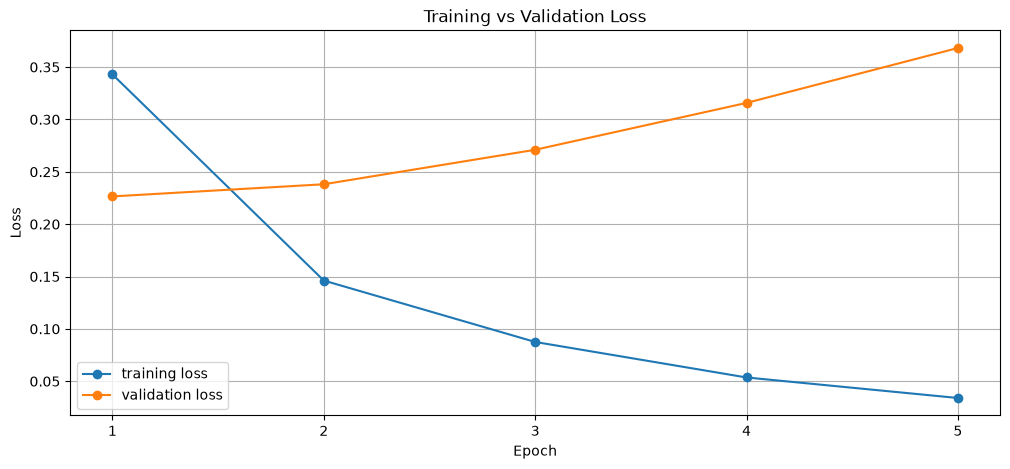

In [27]:
import matplotlib.pyplot as plt

epochs = range(1, 6)

plt.figure(figsize=(12, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="training loss")
plt.plot(epochs, history["val_loss"], marker="o", label="validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid()
plt.show()

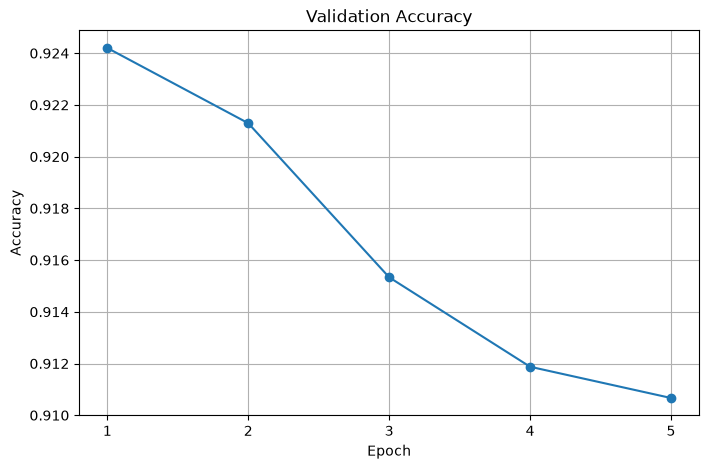

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["val_accuracy"], marker="o")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.xticks(epochs)
plt.grid()
plt.show()

### Experiment: Dropout

In [29]:
class NewsClassifierDropout(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()


        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x):
        return self.network(x)


In [30]:
model_dropout = NewsClassifierDropout(
    input_size=60004,
    hidden_size=128,
    num_classes=4
)

### Running the model on the GPU

In [31]:
model_dropout = model_dropout.to(device)

In [32]:
optimizer_dropout = torch.optim.Adam(
    model_dropout.parameters(),
    lr=0.001
)

In [33]:
loss_function = nn.CrossEntropyLoss()

In [34]:
history_dropout = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

In [35]:
num_epochs = 5

for epoch in range(num_epochs):

    # -----------------------
    # Training
    # -----------------------
    model_dropout.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model_dropout(X_batch)
        loss = loss_function(outputs, y_batch)

        optimizer_dropout.zero_grad()
        loss.backward()
        optimizer_dropout.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples

    # -----------------------
    # Validation
    # -----------------------
    model_dropout.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in dev_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model_dropout(X_batch)
            loss = loss_function(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples

    # -----------------------
    # Save metrics
    # -----------------------
    history_dropout["train_loss"].append(train_loss)
    history_dropout["val_loss"].append(val_loss)
    history_dropout["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 1/5 | Train Loss: 0.3596 | Val Loss: 0.2278 | Val Accuracy: 0.9249
Epoch 2/5 | Train Loss: 0.1601 | Val Loss: 0.2272 | Val Accuracy: 0.9223
Epoch 3/5 | Train Loss: 0.1015 | Val Loss: 0.2498 | Val Accuracy: 0.9210
Epoch 4/5 | Train Loss: 0.0667 | Val Loss: 0.2812 | Val Accuracy: 0.9182
Epoch 5/5 | Train Loss: 0.0447 | Val Loss: 0.3174 | Val Accuracy: 0.9153


Dropout improved the best observed validation accuracy from 92.36% to 92.49% and kept validation loss lower at epoch 2 (0.2272 versus 0.2381 without dropout). Validation performance still declined after the first epoch, so dropout did not eliminate overfitting.

### Experiment: Early stopping

In [36]:
model_dropout_early = NewsClassifierDropout(
    input_size=60004,
    hidden_size=128,
    num_classes=4
).to(device)

optimizer_early = torch.optim.Adam(
    model_dropout_early.parameters(),
    lr=0.001
)

In [37]:
import copy

best_val_loss = float('inf')
best_model_weights = None

patience = 2
epochs_without_improvement = 0

history_early = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

In [38]:
num_epochs = 5

for epoch in range(num_epochs):

    # -----------------------
    # Training
    # -----------------------
    model_dropout_early.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model_dropout_early(X_batch)
        loss = loss_function(outputs, y_batch)

        optimizer_early.zero_grad()
        loss.backward()
        optimizer_early.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples

    # -----------------------
    # Validation
    # -----------------------
    model_dropout_early.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in dev_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model_dropout_early(X_batch)
            loss = loss_function(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(model_dropout_early.state_dict())

        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # -----------------------
    # Save metrics
    # -----------------------
    history_early["train_loss"].append(train_loss)
    history_early["val_loss"].append(val_loss)
    history_early["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )
    if epochs_without_improvement >= patience:
        print("Early stopping triggered")
        break

model_dropout_early.load_state_dict(best_model_weights)

Epoch 1/5 | Train Loss: 0.3621 | Val Loss: 0.2275 | Val Accuracy: 0.9245
Epoch 2/5 | Train Loss: 0.1617 | Val Loss: 0.2270 | Val Accuracy: 0.9233
Epoch 3/5 | Train Loss: 0.1032 | Val Loss: 0.2464 | Val Accuracy: 0.9210
Epoch 4/5 | Train Loss: 0.0677 | Val Loss: 0.2799 | Val Accuracy: 0.9184
Early stopping triggered


<All keys matched successfully>

Early stopping selected the checkpoint with the lowest validation loss (0.2270 at epoch 2). The dropout model had the highest observed validation accuracy (92.49%), while the early-stopped model's peak was 92.45%.

This shows that **loss and accuracy measure different aspects of performance** and need not peak at the same epoch.

In [39]:
print(f"Best validation loss: {best_val_loss}")
print(f"Best epoch: {history_early["val_loss"].index(best_val_loss) + 1}")
print(f"Recorded epochs: {len(history_early["train_loss"])}")

Best validation loss: 0.227012060324351
Best epoch: 2
Recorded epochs: 4


### Comparing the learning curves

In [40]:
print(f"FNN without dropout: {len(history["train_loss"])}")
print(f"FNN with dropout: {len(history_dropout["train_loss"])}")
print(f"FNN with dropout + early stopping: {len(history_early["train_loss"])}")

FNN without dropout: 5
FNN with dropout: 5
FNN with dropout + early stopping: 4


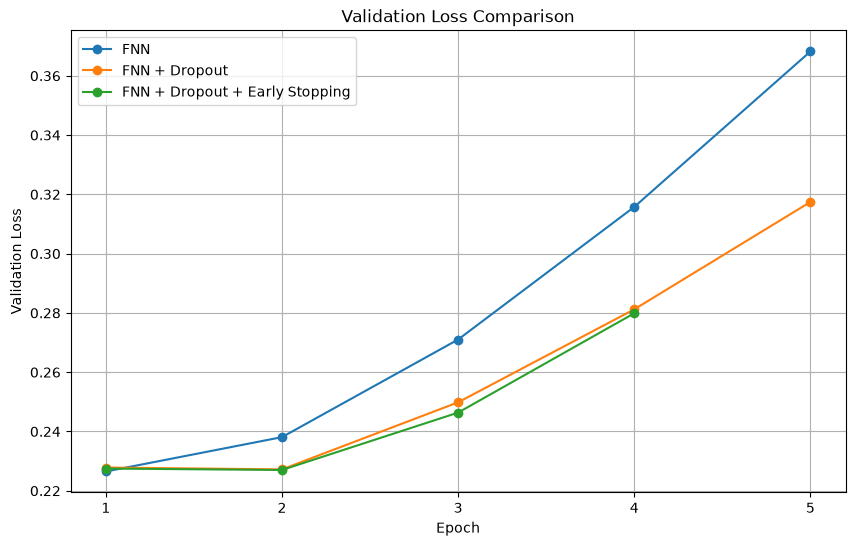

In [41]:
plt.figure(figsize=(10, 6))

plt.plot(history["val_loss"], marker='o', label="FNN")
plt.plot(history_dropout["val_loss"], marker='o', label="FNN + Dropout")
plt.plot(history_early["val_loss"], marker='o', label="FNN + Dropout + Early Stopping")


plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

Dropout modestly delayed overfitting, while early stopping restored the checkpoint with the lowest validation loss. In these runs, dropout achieved the highest validation accuracy (92.49%), and early stopping selected the lowest validation loss (0.2270 at epoch 2).

### Class-wise validation performance

In [42]:
model_dropout_early.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in dev_loader:
        X_batch = X_batch.to(device)

        outputs = model_dropout_early(X_batch)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(y_batch.numpy())


Use the validation predictions and labels to inspect precision, recall, and F1 score for each class.

In [43]:
class_names = ["World", "Sports", "Business", "Sci/Tech"]

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

              precision    recall  f1-score   support

       World       0.93      0.91      0.92      6000
      Sports       0.97      0.98      0.97      6000
    Business       0.89      0.90      0.90      6000
    Sci/Tech       0.90      0.90      0.90      6000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



**Sports** was the strongest class (F1 = 0.97).

**Business** and **Sci/Tech** had the lowest F1 scores (0.90 each), making them useful classes to inspect for errors.

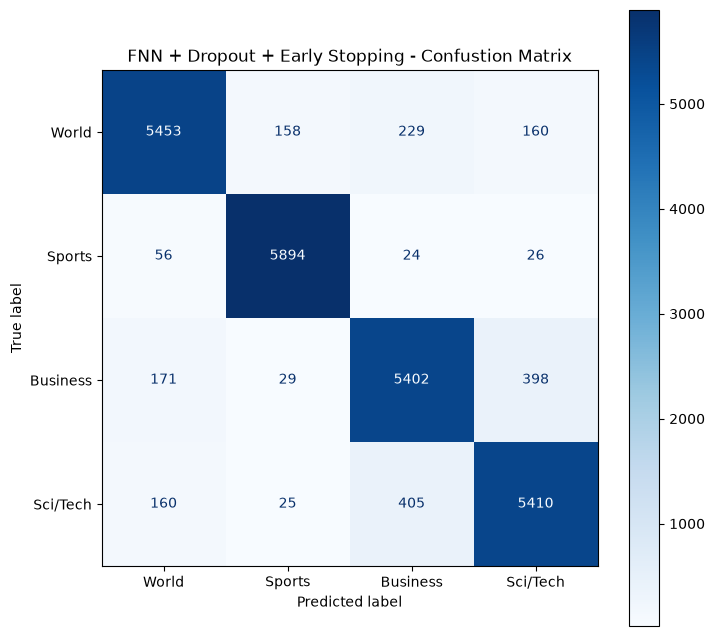

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap="Blues", values_format="d", ax=ax)

plt.title("FNN + Dropout + Early Stopping - Confustion Matrix")
plt.show()

### Inspect articles misclassified between Business and Sci/Tech

In [45]:
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

business_to_scitech = np.where(
    (all_labels == 2) & (all_predictions == 3)
)[0]

scitech_to_business = np.where(
    (all_labels == 3) & (all_predictions == 2)
)[0]


for i in business_to_scitech[:30]:
    print("ACTUAL: Business | PREDICTED: Sci/Tech")
    print(dev_df.iloc[i]["cleaned_text"])
    print("-"*100)
print()
for i in scitech_to_business[:30]:
    print("ACTUAL: Sci/Tech | PREDICTED: Business")
    print(dev_df.iloc[i]["cleaned_text"])
    print("-"*100)

ACTUAL: Business | PREDICTED: Sci/Tech
Dodgers sign Ledee to two-year deal The Los Angeles Dodgers signed Ricky Ledee to a two-year contract Monday, giving them a left-handed pinch-hitter and more depth in the outfield.
----------------------------------------------------------------------------------------------------
ACTUAL: Business | PREDICTED: Sci/Tech
Car bombs claim a dozen lives in Iraq BAGHDAD - A pair of car bomb attacks left at least a dozen people dead in Iraq Tuesday. At least eight died when a car full of explosives crashed into a concrete blast barrier around the Education Ministry building in Baghdad.
----------------------------------------------------------------------------------------------------
ACTUAL: Business | PREDICTED: Sci/Tech
Chinese-Made Cars to Be Sold in U.S. (AP) AP - The man who brought the Yugo and Subaru to this country has a new project  #151; becoming the first mass importer of low-cost Chinese-made cars.
-------------------------------------------

### Experiment 2: Cleaned text

Decode HTML entities and remove common markup, then compare unigram TF-IDF models with the baseline.

In [46]:
import html
import re

def clean_html_artifacts(text):
    while True:
        decoded_text = html.unescape(text)
        if decoded_text == text:
            break
        text = decoded_text

    text = re.sub(r"#36;", "$", text)
    text = re.sub(r"\s*#39;\s*", "'", text)
    text = re.sub(r"\s+amp;\s*", "&", text)
    text = re.sub(r"\s*quot;\s*", '"', text)
    text = re.sub(
        r"</?(?:strong|em|b|i|p|div|br|span)\b[^>]*>",
        " ",
        text,
        flags=re.IGNORECASE
    )
    return re.sub(r"\s+", " ", text).strip()

In [47]:
full_train_df = pd.DataFrame(dataset["train"])

full_train_df["cleaned_text"] = full_train_df["text"].str.replace(
    "\\", " ", regex=False
)

full_train_df["experiment_text"] = full_train_df["cleaned_text"].apply(
    clean_html_artifacts
)

train_df["experiment_text"] = full_train_df.loc[
    train_df.index, "experiment_text"
]

dev_df["experiment_text"] = full_train_df.loc[
    dev_df.index, "experiment_text"
]

In [48]:
print(train_df["experiment_text"].head(3))
print(dev_df["experiment_text"].head(3))
print(train_df["experiment_text"].isna().sum())
print(dev_df["experiment_text"].isna().sum())

51238    Clijsters Unsure About Latest Injury, Says Hew...
32395    Earthquake Swarm Shakes Eastern Sierra (AP) AP...
54318    Issues related to war in Iraq help define elec...
Name: experiment_text, dtype: str
112486    Wall Street's Designs on '05? A Merger Boom Af...
109163    Dodgers sign Ledee to two-year deal The Los An...
6638      Olympians pursuit of marketing gold begins lon...
Name: experiment_text, dtype: str
0
0


In [49]:
vectorizer_exp2 = TfidfVectorizer()

X_train_exp2 = vectorizer_exp2.fit_transform(train_df["experiment_text"])
X_dev_exp2 = vectorizer_exp2.transform(dev_df["experiment_text"])

y_train_exp2 = train_df["label"]
y_dev_exp2 = dev_df["label"]

print("Train shape:", X_train_exp2.shape)
print("Dev shape:", X_dev_exp2.shape)

Train shape: (96000, 60003)
Dev shape: (24000, 60003)


In [50]:
class NewsDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = torch.tensor(y.to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        x = self.X[index].toarray().flatten()
        x = torch.tensor(x, dtype=torch.float32)
        return x, self.y[index]

In [51]:
train_dataset_exp2 = NewsDataset(X_train_exp2, y_train_exp2)
dev_dataset_exp2 = NewsDataset(X_dev_exp2, y_dev_exp2)

In [52]:
train_loader_exp2 = DataLoader(
    train_dataset_exp2,
    batch_size=64,
    shuffle=True
)

dev_loader_exp2 = DataLoader(
    dev_dataset_exp2,
    batch_size=64,
    shuffle=False
)

In [53]:
X_batch, y_batch = next(iter(train_loader_exp2))

print("Input shape:", X_batch.shape)
print("Label shape:", y_batch.shape)
print("Input dtype:", X_batch.dtype)
print("Label dtype:", y_batch.dtype)

Input shape: torch.Size([64, 60003])
Label shape: torch.Size([64])
Input dtype: torch.float32
Label dtype: torch.int64


In [54]:
model_exp2 = NewsClassifier(
    input_size=X_train_exp2.shape[1],
    hidden_size=128,
    num_classes=4
).to(device)

loss_function_exp2 = nn.CrossEntropyLoss()

optimizer_exp2 = torch.optim.Adam(
    model_exp2.parameters(),
    lr=0.001
)

In [55]:
history_exp2 = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

In [56]:
num_epochs = 5

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model_exp2.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader_exp2:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_exp2.zero_grad()

        outputs = model_exp2(X_batch)
        loss = loss_function_exp2(outputs, y_batch)

        loss.backward()
        optimizer_exp2.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples

    # --------------------
    # Validation
    # --------------------
    model_exp2.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in dev_loader_exp2:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model_exp2(X_batch)
            loss = loss_function_exp2(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples

    # --------------------
    # Save metrics
    # --------------------
    history_exp2["train_loss"].append(train_loss)
    history_exp2["val_loss"].append(val_loss)
    history_exp2["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/5] Train Loss: 0.3436 | Val Loss: 0.2304 | Val Accuracy: 0.9237
Epoch [2/5] Train Loss: 0.1479 | Val Loss: 0.2414 | Val Accuracy: 0.9215
Epoch [3/5] Train Loss: 0.0891 | Val Loss: 0.2752 | Val Accuracy: 0.9155
Epoch [4/5] Train Loss: 0.0553 | Val Loss: 0.3232 | Val Accuracy: 0.9115
Epoch [5/5] Train Loss: 0.0358 | Val Loss: 0.3710 | Val Accuracy: 0.9110


In [57]:
model_exp2_dropout = NewsClassifierDropout(
    input_size=X_train_exp2.shape[1],
    hidden_size=128,
    num_classes=4
).to(device)

loss_function_exp2_dropout = nn.CrossEntropyLoss()

optimizer_exp2_dropout = torch.optim.Adam(
    model_exp2_dropout.parameters(),
    lr=0.001
)

history_exp2_dropout = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

In [58]:
num_epochs = 5

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model_exp2_dropout.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader_exp2:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_exp2_dropout.zero_grad()

        outputs = model_exp2_dropout(X_batch)
        loss = loss_function_exp2_dropout(outputs, y_batch)

        loss.backward()
        optimizer_exp2_dropout.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples

    # --------------------
    # Validation
    # --------------------
    model_exp2_dropout.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in dev_loader_exp2:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model_exp2_dropout(X_batch)
            loss = loss_function_exp2_dropout(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples

    # --------------------
    # Save metrics
    # --------------------
    history_exp2_dropout["train_loss"].append(train_loss)
    history_exp2_dropout["val_loss"].append(val_loss)
    history_exp2_dropout["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/5] Train Loss: 0.3641 | Val Loss: 0.2301 | Val Accuracy: 0.9238
Epoch [2/5] Train Loss: 0.1626 | Val Loss: 0.2303 | Val Accuracy: 0.9237
Epoch [3/5] Train Loss: 0.1034 | Val Loss: 0.2553 | Val Accuracy: 0.9201
Epoch [4/5] Train Loss: 0.0690 | Val Loss: 0.2890 | Val Accuracy: 0.9159
Epoch [5/5] Train Loss: 0.0466 | Val Loss: 0.3221 | Val Accuracy: 0.9154


### Experiment 3: Unigrams and bigrams

Keep the cleaned text and model setup, and extend TF-IDF to include bigrams with a 100,000-feature limit.

In [59]:
vectorizer_exp3 = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100_000
)

X_train_exp3 = vectorizer_exp3.fit_transform(
    train_df["experiment_text"]
)

X_dev_exp3 = vectorizer_exp3.transform(
    dev_df["experiment_text"]
)

y_train_exp3 = train_df["label"]
y_dev_exp3 = dev_df["label"]

y_test_exp3 = test_df["label"]
print(X_train_exp3.shape)
print(y_train_exp3.shape)

print(X_dev_exp3.shape)
print(y_dev_exp3.shape)

(96000, 100000)
(96000,)
(24000, 100000)
(24000,)


In [60]:
train_dataset_exp3 = NewsDataset(X_train_exp3, y_train_exp3)
dev_dataset_exp3 = NewsDataset(X_dev_exp3, y_dev_exp3)

In [61]:
train_loader_exp3 = DataLoader(
    train_dataset_exp3,
    batch_size=64,
    shuffle=True
)

dev_loader_exp3 = DataLoader(
    dev_dataset_exp3,
    batch_size=64,
    shuffle=False
)

In [62]:
X_batch, y_batch = next(iter(train_loader_exp3))

print("Input shape:", X_batch.shape)
print("Label shape:", y_batch.shape)
print("Input dtype:", X_batch.dtype)
print("Label dtype:", y_batch.dtype)

Input shape: torch.Size([64, 100000])
Label shape: torch.Size([64])
Input dtype: torch.float32
Label dtype: torch.int64


In [63]:
model_exp3 = NewsClassifier(
    input_size=X_train_exp3.shape[1],
    hidden_size=128,
    num_classes=4
).to(device)

loss_function_exp3 = nn.CrossEntropyLoss()

optimizer_exp3 = torch.optim.Adam(
    model_exp3.parameters(),
    lr=0.001
)

history_exp3 = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

In [64]:
total_params = sum(p.numel() for p in model_exp3.parameters())

print(f"Total parameters: {total_params:,}")
print(f"GPU allocated memory: {torch.cuda.memory_allocated() / 1024**2:.2f} MiB")

Total parameters: 12,800,644
GPU allocated memory: 678.89 MiB


In [65]:
num_epochs = 5

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model_exp3.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader_exp3:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_exp3.zero_grad()

        outputs = model_exp3(X_batch)
        loss = loss_function_exp3(outputs, y_batch)

        loss.backward()
        optimizer_exp3.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples

    # --------------------
    # Validation
    # --------------------
    model_exp3.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in dev_loader_exp3:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model_exp3(X_batch)
            loss = loss_function_exp3(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples

    # --------------------
    # Save metrics
    # --------------------
    history_exp3["train_loss"].append(train_loss)
    history_exp3["val_loss"].append(val_loss)
    history_exp3["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/5] Train Loss: 0.3380 | Val Loss: 0.2277 | Val Accuracy: 0.9235
Epoch [2/5] Train Loss: 0.0983 | Val Loss: 0.2612 | Val Accuracy: 0.9157
Epoch [3/5] Train Loss: 0.0376 | Val Loss: 0.3148 | Val Accuracy: 0.9137
Epoch [4/5] Train Loss: 0.0217 | Val Loss: 0.3512 | Val Accuracy: 0.9130
Epoch [5/5] Train Loss: 0.0156 | Val Loss: 0.3847 | Val Accuracy: 0.9107


In [66]:
model_exp3_early = NewsClassifier(
    input_size=X_train_exp3.shape[1],
    hidden_size=128,
    num_classes=4
).to(device)

loss_function_exp3_early = nn.CrossEntropyLoss()

optimizer_exp3_early = torch.optim.Adam(
    model_exp3_early.parameters(),
    lr=0.001
)

In [67]:
best_val_loss = float("inf")
best_model_weights = None

patience = 2
epochs_without_improvement = 0

num_epochs = 5

history_exp3_early = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

In [68]:
for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model_exp3_early.train()

    train_total_loss = 0
    train_total_samples = 0

    for X_batch, y_batch in train_loader_exp3:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_exp3_early.zero_grad()

        outputs = model_exp3_early(X_batch)
        loss = loss_function_exp3_early(outputs, y_batch)

        loss.backward()
        optimizer_exp3_early.step()

        train_total_loss += loss.item() * X_batch.size(0)
        train_total_samples += X_batch.size(0)

    train_loss = train_total_loss / train_total_samples

    # --------------------
    # Validation
    # --------------------
    model_exp3_early.eval()

    val_total_loss = 0
    val_total_correct = 0
    val_total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in dev_loader_exp3:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model_exp3_early(X_batch)
            loss = loss_function_exp3_early(outputs, y_batch)

            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * X_batch.size(0)
            val_total_correct += (predictions == y_batch).sum().item()
            val_total_samples += X_batch.size(0)

    val_loss = val_total_loss / val_total_samples
    val_accuracy = val_total_correct / val_total_samples

    # --------------------
    # Save metrics
    # --------------------
    history_exp3_early["train_loss"].append(train_loss)
    history_exp3_early["val_loss"].append(val_loss)
    history_exp3_early["val_accuracy"].append(val_accuracy)

    # --------------------
    # Early stopping
    # --------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            model_exp3_early.state_dict()
        )

        best_epoch = epoch + 1
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping triggered!")
        break

# --------------------
# Restore best weights
# --------------------
model_exp3_early.load_state_dict(best_model_weights)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [1/5] Train Loss: 0.3362 | Val Loss: 0.2295 | Val Accuracy: 0.9238
Epoch [2/5] Train Loss: 0.0966 | Val Loss: 0.2594 | Val Accuracy: 0.9160
Epoch [3/5] Train Loss: 0.0363 | Val Loss: 0.3106 | Val Accuracy: 0.9151
Early stopping triggered!

Best epoch: 1
Best validation loss: 0.2295


In [69]:
model_exp3_early.eval()

all_predictions_exp3 = []
all_labels_exp3 = []

with torch.no_grad():

    for X_batch, y_batch in dev_loader_exp3:

        X_batch = X_batch.to(device)

        outputs = model_exp3_early(X_batch)

        predictions = outputs.argmax(dim=1)

        all_predictions_exp3.extend(
            predictions.cpu().numpy()
        )

        all_labels_exp3.extend(
            y_batch.numpy()
        )

In [70]:
print("Predictions:", len(all_predictions_exp3))
print("Actual labels:", len(all_labels_exp3))

Predictions: 24000
Actual labels: 24000


In [71]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels_exp3,
        all_predictions_exp3,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

              precision    recall  f1-score   support

       World       0.94      0.90      0.92      6000
      Sports       0.96      0.99      0.97      6000
    Business       0.91      0.88      0.90      6000
    Sci/Tech       0.89      0.92      0.90      6000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



Text(0.5, 36.38563368055554, 'Predicted label')

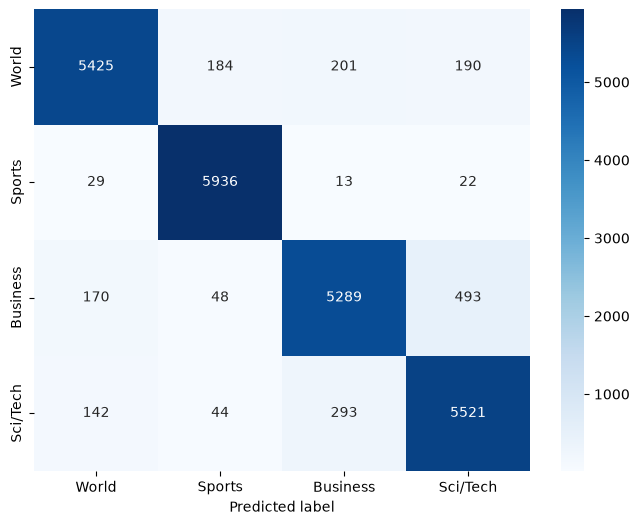

In [72]:
import seaborn as sns

cm_exp3 = confusion_matrix(
    all_labels_exp3,
    all_predictions_exp3
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_exp3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["World", "Sports", "Business", "Sci/Tech"],
    yticklabels=["World", "Sports", "Business", "Sci/Tech"]
)

plt.xlabel("Predicted label")

In [73]:
cm_exp3

array([[5425,  184,  201,  190],
       [  29, 5936,   13,   22],
       [ 170,   48, 5289,  493],
       [ 142,   44,  293, 5521]])

In [74]:
# Apply the same preprocessing used for Experiment 3
test_df["cleaned_text"] = test_df["text"].str.replace(
    "\\", " ", regex=False
)

test_df["experiment_text"] = test_df["cleaned_text"].apply(
    clean_html_artifacts
)

# Transform using the EXISTING fitted vectorizer
X_test_exp3 = vectorizer_exp3.transform(
    test_df["experiment_text"]
)

y_test_exp3 = test_df["label"]

print("Test features:", X_test_exp3.shape)
print("Test labels:", y_test_exp3.shape)

Test features: (7600, 100000)
Test labels: (7600,)


In [75]:
test_dataset_exp3 = NewsDataset(
    X_test_exp3,
    y_test_exp3
)

test_loader_exp3 = DataLoader(
    test_dataset_exp3,
    batch_size=64,
    shuffle=False
)

X_batch, y_batch = next(iter(test_loader_exp3))

print("Features shape:", X_batch.shape)
print("Labels shape:", y_batch.shape)

Features shape: torch.Size([64, 100000])
Labels shape: torch.Size([64])


In [76]:
model_exp3_early.eval()

all_test_predictions = []
all_test_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader_exp3:
        X_batch = X_batch.to(device)

        outputs = model_exp3_early(X_batch)
        predictions = outputs.argmax(dim=1)

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )
        all_test_labels.extend(
            y_batch.numpy()
        )

print("Predictions:", len(all_test_predictions))
print("Actual labels:", len(all_test_labels))

Predictions: 7600
Actual labels: 7600


In [77]:
from sklearn.metrics import accuracy_score, classification_report

test_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(
    classification_report(
        all_test_labels,
        all_test_predictions,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Test accuracy: 0.9196
Test accuracy: 91.96%

Classification Report:

              precision    recall  f1-score   support

       World       0.94      0.90      0.92      1900
      Sports       0.95      0.99      0.97      1900
    Business       0.90      0.87      0.89      1900
    Sci/Tech       0.88      0.91      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



In [78]:
from sklearn.linear_model import LogisticRegression

lr_exp3 = LogisticRegression(max_iter=1000)

lr_exp3.fit(X_train_exp3, y_train_exp3)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [79]:
lr_test_predictions = lr_exp3.predict(X_test_exp3)

lr_test_accuracy = accuracy_score(
    y_test_exp3,
    lr_test_predictions
)

print(f"Logistic Regression test accuracy: {lr_test_accuracy:.4f}")
print(f"Logistic Regression test accuracy: {lr_test_accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_exp3,
        lr_test_predictions,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Logistic Regression test accuracy: 0.9139
Logistic Regression test accuracy: 91.39%

Classification Report:

              precision    recall  f1-score   support

       World       0.93      0.90      0.92      1900
      Sports       0.95      0.98      0.96      1900
    Business       0.88      0.88      0.88      1900
    Sci/Tech       0.89      0.90      0.89      1900

    accuracy                           0.91      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.91      0.91      7600



In [80]:
names_to_check = [
    "vectorizer_exp3",
    "lr_exp3",
    "model_exp3_early",
    "best_model",
    "model",
    "device"
]

for name in names_to_check:
    print(f"{name}: {name in globals()}")

vectorizer_exp3: True
lr_exp3: True
model_exp3_early: True
best_model: False
model: True
device: True


In [82]:
import joblib

joblib.dump(
    vectorizer_exp3,
    "../models/tfidf_vectorizer.joblib"
)

torch.save(
    model_exp3_early.state_dict(),
    "../models/fnn_weights.pth"
)